# MAE +16 · Fixed versus rolling RankMe

**Complete** · 3 of 3 seeds · 1,434 forecast origins per seed on the Phase 1.2 correlated walk.

Each predictor estimates how much the first action changes terminal RankMe compared with skipping that action. The remaining 15 arrivals use 0.25× LR in all branches. Models share the same 88 pre-action inputs, action history, calibration origins and future frames. Only the RankMe output among the four predicted measurements differs by bank. The action schedule is replayed from the original +16 run. Rollout optimizers are isolated during calibration and evaluation. The replay follows the archived actions on its own learner states, which can differ from the archived weights because the earlier rollout path could share optimizer tensors.

## Forecast errors and action ranking

| RankMe bank | Online RMSE | Frozen RMSE | Zero-effect RMSE | Online skill | Frozen skill | Online action agreement | Frozen action agreement |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Rolling 128 | 0.036395 | 0.047203 | 0.037990 | 4.2% | -24.3% | 59.5% | 55.8% |
| Fixed 128 | 0.027050 | 0.031669 | 0.028021 | 3.5% | -13.0% | 58.3% | 54.5% |
| Fixed P1.2 900 | 0.028790 | 0.034564 | 0.029771 | 3.3% | -16.1% | 58.3% | 54.3% |

Skill is the reduction in RMSE relative to predicting zero action advantage. A negative score means higher error than that baseline. Action agreement tests all three paired action orderings and omits realized ties within 0.00001 RankMe units.

## Does the fixed bank improve forecast skill?

| Bank comparison | Online skill difference (pp) | Paired 95% interval (pp) |
| --- | ---: | ---: |
| Fixed 128 vs Rolling 128 | -0.73 | [-1.59, +0.18] |
| Fixed P1.2 900 vs Rolling 128 | -0.90 | [-1.77, -0.01] |
| Fixed P1.2 900 vs Fixed 128 | -0.17 | [-0.75, +0.44] |

The bootstrap resamples paired contiguous blocks of 2,048 arrivals within each archived seed. Intervals condition on the bank images and the archived walks.

### Online skill by seed

| Seed | Rolling 128 | Fixed 128 | Fixed P1.2 900 |
| --- | ---: | ---: | ---: |
| 2026 | +4.60% | +3.65% | +3.61% |
| 2027 | +4.10% | +1.84% | +2.31% |
| 2028 | +3.97% | +5.39% | +4.30% |

## Forecast error over the walk

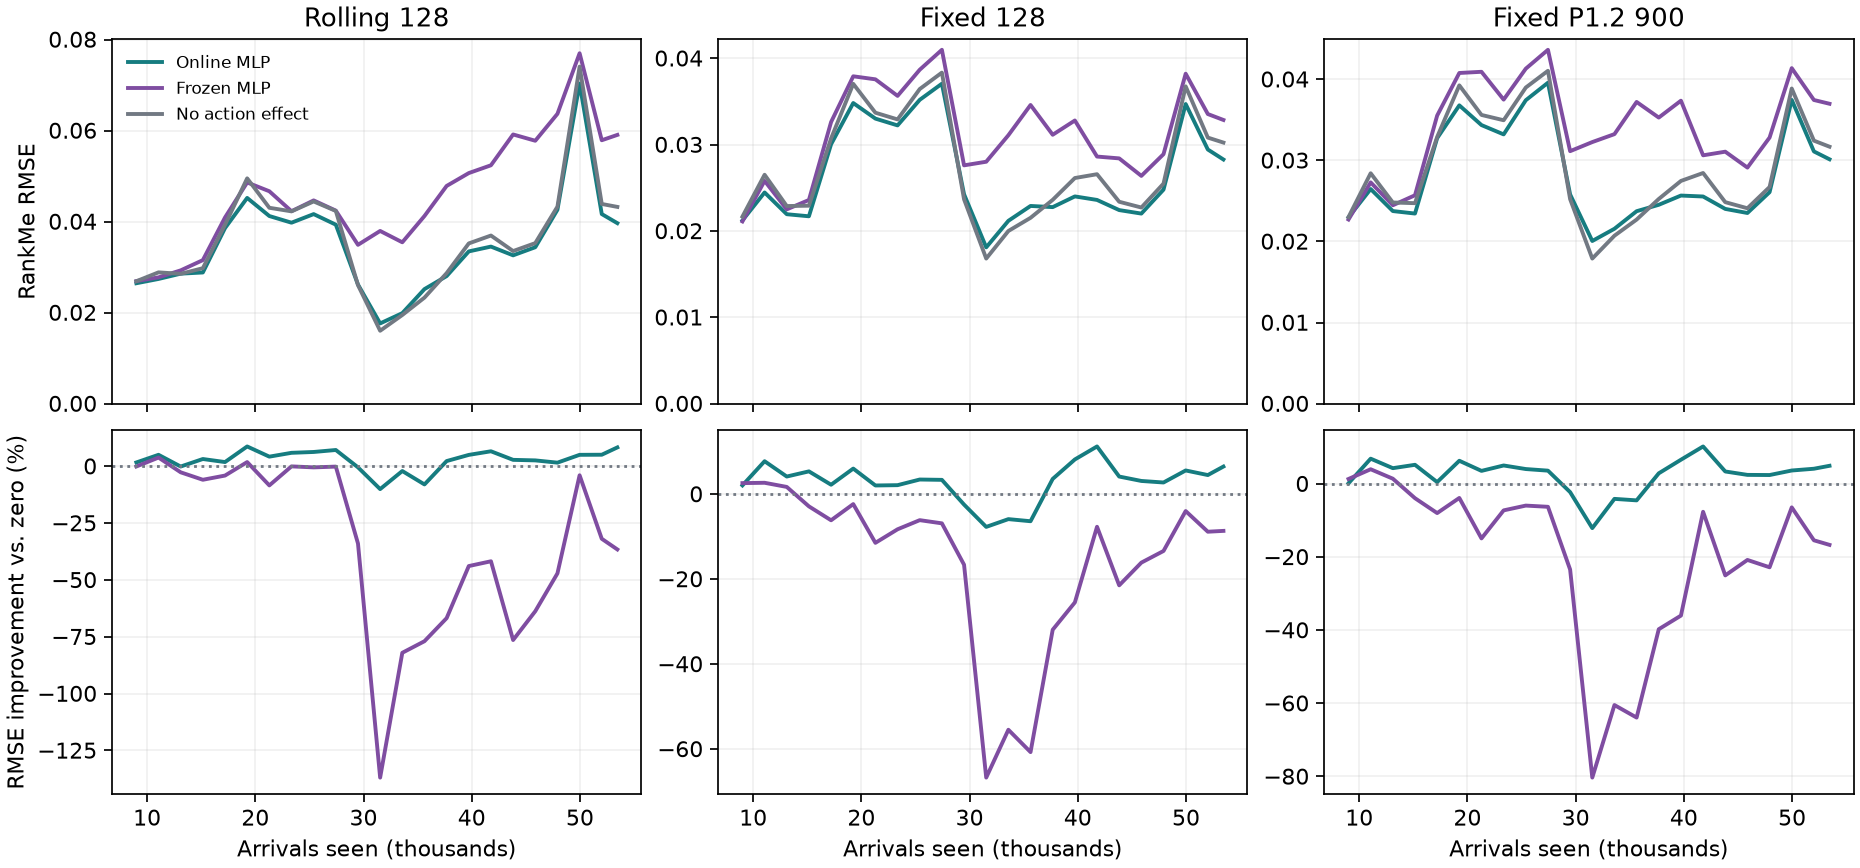

The top row shows absolute errors. The bottom row accounts for the fact that each bank can have a different sized action signal.

## Timing and data separation

The fixed bank is the original 900 disjoint Phase 1.2 query images per seed. A label-free draw of 128 of these images isolates fixed membership at the rolling bank size. The same fixed images are used for calibration and evaluation on later arrivals. The estimated skill is temporal generalization on those registered images.

All calibration action outcomes mature within the first 8,000 arrivals. Evaluation starts at arrival 8,000. All online forecasts are issued before the corresponding action and trained only after the last of 16 arrivals has been seen. The frozen models keep their calibration weights. Evaluation samples every 32 arrivals, so online predictors receive one matched feedback update per scored origin. All three banks use this cadence.